In [1273]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import numpy as np

In [1274]:
ConnectX_Churn = pd.read_csv("/content/drive/MyDrive/IDS_Lab_7_datasets/ConnectX_Churn.csv")
loan_approval = pd.read_csv("/content/drive/MyDrive/IDS_Lab_7_datasets/loan_approval.csv")

In [1275]:
ConnectX_Churn.shape

(5000, 10)

In [1276]:
loan_approval.shape

(974, 13)

In [1277]:
ConnectX_Churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Gender           4838 non-null   object 
 2   Age              5000 non-null   int64  
 3   Tenure           5000 non-null   int64  
 4   InternetService  4861 non-null   object 
 5   MonthlyCharges   5000 non-null   float64
 6   TotalCharges     5000 non-null   float64
 7   Contract         5000 non-null   object 
 8   PaymentMethod    4841 non-null   object 
 9   Churn            5000 non-null   int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 390.8+ KB


In [1278]:
loan_approval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 974 entries, 0 to 973
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            974 non-null    object 
 1   Gender             913 non-null    object 
 2   Married            936 non-null    object 
 3   Dependents         913 non-null    object 
 4   Education          974 non-null    object 
 5   Self_Employed      927 non-null    object 
 6   ApplicantIncome    974 non-null    int64  
 7   CoapplicantIncome  974 non-null    object 
 8   LoanAmount         974 non-null    int64  
 9   Loan_Amount_Term   929 non-null    float64
 10  Credit_History     883 non-null    float64
 11  Property_Area      974 non-null    object 
 12  Loan_Status        974 non-null    object 
dtypes: float64(2), int64(2), object(9)
memory usage: 99.1+ KB


In [1279]:
loan_approval.head(15)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LN0229,Female,Yes,1,Graduate,No,4035,2538,359,120.0,1.0,Urban,Y
1,LN0451,Female,Yes,1,Not Graduate,No,9038,3814,389,360.0,0.0,Rural,N
2,LN1229,NaN,Yes,0,Not Graduate,No,5644,627,127,180.0,1.0,Semiurban,Y
3,LN0675,Male,No,1,Graduate,Yes,7949,439,140,120.0,1.0,Semiurban,Y
4,LN1312,Female,No,1,Graduate,No,3500,832,183,360.0,1.0,Rural,Y
5,LN0904,Female,Yes,0,Graduate,No,9556,3970,377,240.0,1.0,Rural,Y
6,LN1610,Female,NaN,1,Graduate,No,5084,1059,303,180.0,1.0,Rural,Y
7,LN1494,Male,No,0,Graduate,No,4991,1278,135,360.0,1.0,Semiurban,Y
8,LN1624,NaN,No,2,Graduate,No,2700,2990,80,60.0,1.0,Semiurban,Y
9,LN0466,Male,Yes,0,Graduate,No,7641,1967,105,360.0,0.0,Urban,Y


In [1280]:
ConnectX_Churn.head(15)

,CustomerID,Gender,Age,Tenure,InternetService,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Churn
0,1,Male,68,65,DSL,27.68,1827.83,Month-to-month,Bank transfer,0
1,2,Female,64,53,No,59.29,3133.66,One year,Electronic check,0
2,3,Male,64,26,Fiber optic,86.99,2281.39,Two year,Mailed check,1
3,4,Male,21,37,Fiber optic,66.99,2479.35,Two year,Electronic check,0
4,5,Male,24,57,Fiber optic,58.37,3301.21,One year,Bank transfer,0
5,6,Female,62,61,Fiber optic,31.92,1976.74,One year,Credit card,1
6,7,Male,52,45,DSL,44.49,1960.47,Month-to-month,Mailed check,0
7,8,Male,65,10,Fiber optic,30.01,302.59,One year,Electronic check,0
8,9,Male,26,71,Fiber optic,100.75,7124.14,Two year,Mailed check,1
9,10,Female,25,7,Fiber optic,33.52,191.35,Month-to-month,Credit card,1


In [1281]:
ConnectX_Churn.isnull().sum()

,0
CustomerID,0
Gender,162
Age,0
Tenure,0
InternetService,139
MonthlyCharges,0
TotalCharges,0
Contract,0
PaymentMethod,159
Churn,0


In [1282]:
loan_approval.isnull().sum()

,0
Loan_ID,0
Gender,61
Married,38
Dependents,61
Education,0
Self_Employed,47
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,45


In [1283]:
ConnectX_Churn["Gender"] = ConnectX_Churn["Gender"].fillna(ConnectX_Churn["Gender"].mode()[0])
ConnectX_Churn["InternetService"] = ConnectX_Churn["InternetService"].fillna(ConnectX_Churn['InternetService'].mode()[0])
ConnectX_Churn["PaymentMethod"] = ConnectX_Churn["PaymentMethod"].fillna(ConnectX_Churn['PaymentMethod'].mode()[0])
ConnectX_Churn.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Tenure,0
InternetService,0
MonthlyCharges,0
TotalCharges,0
Contract,0
PaymentMethod,0
Churn,0


In [1284]:
loan_approval.duplicated().sum()

np.int64(0)

In [1285]:
ConnectX_Churn.duplicated().sum()

np.int64(0)

In [1286]:
for i in ConnectX_Churn.keys():
  print(f"Value Counts for {i}: \n\n", ConnectX_Churn[i].value_counts(dropna=False), f"\n\nUnique for {i}: \n\n", ConnectX_Churn[i].unique(), "\n\nNegatives:\n", ConnectX_Churn[ConnectX_Churn[i] < 0] if pd.api.types.is_numeric_dtype(ConnectX_Churn[i]) else None)

Value Counts for CustomerID: 

 CustomerID
5000    1
1       1
2       1
3       1
4       1
       ..
13      1
12      1
11      1
10      1
9       1
Name: count, Length: 5000, dtype: int64 

Unique for CustomerID: 

 [   1    2    3 ... 4998 4999 5000] 

Negatives:
 Empty DataFrame
Columns: [CustomerID, Gender, Age, Tenure, InternetService, MonthlyCharges, TotalCharges, Contract, PaymentMethod, Churn]
Index: []
Value Counts for Gender: 

 Gender
Female    2583
Male      2417
Name: count, dtype: int64 

Unique for Gender: 

 ['Male' 'Female'] 

Negatives:
 None
Value Counts for Age: 

 Age
34    119
62    115
40    114
30    113
64    111
43    109
49    106
35    106
33    105
59    105
21    104
45    103
66    101
32    101
36    101
46    100
55    100
57    100
39    100
37     98
29     97
51     97
65     97
27     96
38     96
20     95
42     94
52     94
69     94
61     94
19     93
23     93
60     93
24     92
53     91
56     91
18     90
41     90
47     90
28     89


In [1287]:
for i in loan_approval.keys():
  print("Value Counts:\n\n", loan_approval[i].value_counts(dropna=False), "\n\nUnique:\n", loan_approval[i].unique(), "\n\nNegatives:\n", loan_approval[loan_approval[i] < 0] if pd.api.types.is_numeric_dtype(loan_approval[i]) else "No Negatives")

Value Counts:

 Loan_ID
LN1020    1
LN0229    1
LN0451    1
LN1229    1
LN0675    1
         ..
LN1690    1
LN1781    1
LN0816    1
LN0671    1
LN0647    1
Name: count, Length: 974, dtype: int64 

Unique:
 ['LN0229' 'LN0451' 'LN1229' 'LN0675' 'LN1312' 'LN0904' 'LN1610' 'LN1494'
 'LN1624' 'LN0466' 'LN0942' 'LN1504' 'LN1030' 'LN1827' 'LN0647' 'LN0671'
 'LN0816' 'LN1781' 'LN1690' 'LN1520' 'LN0089' 'LN1868' 'LN0749' 'LN0720'
 'LN0990' 'LN1116' 'LN0046' 'LN0118' 'LN1104' 'LN1010' 'LN0441' 'LN0416'
 'LN0297' 'LN0528' 'LN1421' 'LN1721' 'LN0312' 'LN0475' 'LN1017' 'LN1533'
 'LN1303' 'LN1716' 'LN1674' 'LN0365' 'LN0018' 'LN1326' 'LN1177' 'LN1078'
 'LN0465' 'LN0438' 'LN1147' 'LN0212' 'LN1395' 'LN0439' 'LN1213' 'LN1986'
 'LN0813' 'LN1160' 'LN1763' 'LN0221' 'LN1874' 'LN1890' 'LN1544' 'LN1783'
 'LN1794' 'LN1001' 'LN1593' 'LN1034' 'LN0360' 'LN1497' 'LN0100' 'LN1715'
 'LN1378' 'LN0890' 'LN0440' 'LN0555' 'LN1418' 'LN1471' 'LN1689' 'LN0526'
 'LN1474' 'LN1901' 'LN1283' 'LN1824' 'LN0387' 'LN1077' 'LN0573' 

In [1288]:
loan_approval["CoapplicantIncome"] = loan_approval["CoapplicantIncome"].replace("unknown", pd.NA)
loan_approval['CoapplicantIncome'] = pd.to_numeric(loan_approval['CoapplicantIncome'], errors="coerce")
print("Unique:\n", loan_approval['CoapplicantIncome'].unique())

Unique:
 [2538. 3814.  627.  439.  832. 3970. 1059. 1278. 2990. 1967. 1138. 3595.
  340. 2966.  740.  937. 3701. 1213.  985. 1161.  287. 3070. 1623. 2517.
 2164. 1556. 2531. 3879.   68. 1808. 1564. 3346.   nan 2526. 3716. 3006.
 3158. 1211. 1735.  510. 1265. 1767. 1168. 2868. 2486. 2873.  521. 2035.
  259. 1267. 1433.  745.  933.  992. 1910. 3605.   58. 2696. 3254. 3806.
 3348.  737. 1467. 1398. 3260. 3795. 1351. 2551. 1271.   61. 3819. 2114.
  574. 1847. 2475.  174. 3368. 2366. 1376. 2073. 2341. 3046. 3956.  184.
 2795. 2121.  934. 3092. 3985. 3547. 1823.   70. 3580.  941. 1327.  766.
 2680. 1965. 1581. 1779.  529. 3201. 2874. 3594. 1854. 1937. 1612. 3063.
  541. 2271. 3818. 2610. 2192.  887. 3433. 2993. 3076.   78. 2584.  386.
 3440. 2636. 3478. 2617. 2415.  605.  701. 2684. 3109. 1565. 2383.  459.
 3675. 1389. 3845. 1927. 3238. 3167. 1699. 1248. 1552.  248. 1895. 2995.
 2533. 2640.  318. 1724. 2975.  800.  716. 1215. 1207. 3753. 1852.  633.
 1588.  161.  995. 2652. 1280. 2071. 1787.

In [1289]:

loan_approval["CoapplicantIncome"] = loan_approval["CoapplicantIncome"].fillna(loan_approval["CoapplicantIncome"].median())
loan_approval["Gender"] = loan_approval["Gender"].fillna(loan_approval["Gender"].mode()[0])
loan_approval["Married"] = loan_approval["Married"].fillna(loan_approval['Married'].mode()[0])
loan_approval["Dependents"] = loan_approval["Dependents"].fillna(loan_approval['Dependents'].mode()[0])
loan_approval["Self_Employed"] = loan_approval["Self_Employed"].fillna(loan_approval["Self_Employed"].mode()[0])
loan_approval["Loan_Amount_Term"] = loan_approval["Loan_Amount_Term"].fillna(loan_approval['Loan_Amount_Term'].mode()[0])
loan_approval["Credit_History"] = loan_approval["Credit_History"].fillna(loan_approval['Credit_History'].mode()[0])
loan_approval.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [1290]:
for i, value in enumerate(loan_approval['LoanAmount']):
  loan_approval.at[i,"LoanAmount"] = abs(value)
print(loan_approval[loan_approval["LoanAmount"] < 0])

Empty DataFrame
Columns: [Loan_ID, Gender, Married, Dependents, Education, Self_Employed, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History, Property_Area, Loan_Status]
Index: []


In [1291]:
for i, value in enumerate(ConnectX_Churn["TotalCharges"]):
  ConnectX_Churn.at[i, "TotalCharges"] = abs(value)

ConnectX_Churn[ConnectX_Churn["TotalCharges"] < 0]

,CustomerID,Gender,Age,Tenure,InternetService,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Churn


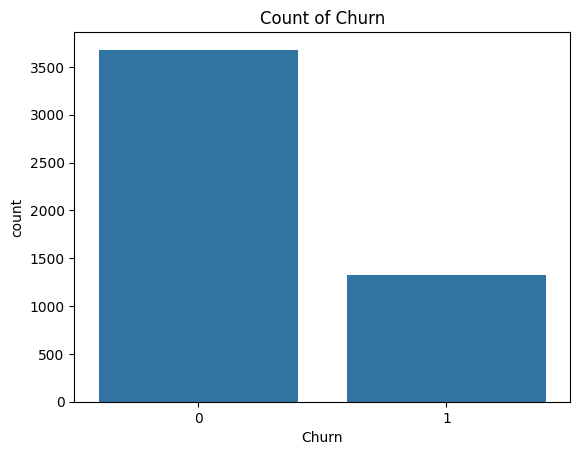

In [1292]:
sns.countplot(x="Churn", data = ConnectX_Churn)
plt.title("Count of Churn")
plt.show()

In [1293]:
ratio = ConnectX_Churn.groupby("Contract")["Churn"].agg(["sum", "count"])
ratio["ChurnRate"] = ratio["sum"] / ratio["count"]
print("Churn Ratio of Contract Types\n", ratio)

Churn Ratio of Contract Types
                 sum  count  ChurnRate
Contract                             
Month-to-month  811   3038   0.266952
One year        325   1295   0.250965
Two year        184    667   0.275862


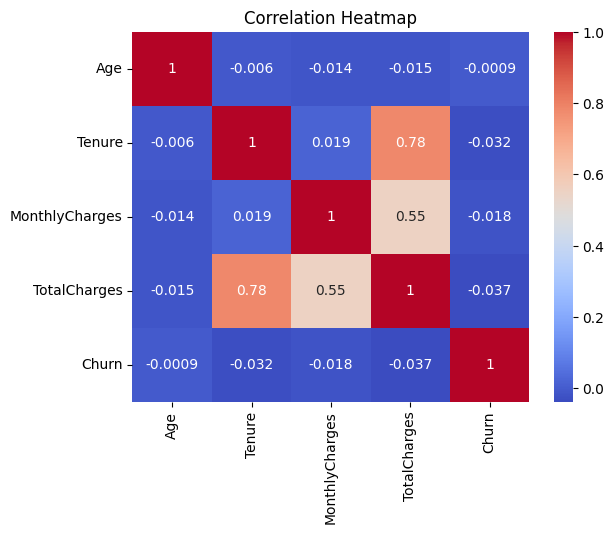

In [1294]:
sns.heatmap(ConnectX_Churn[["Age", "Tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr(), annot = True, cmap = "coolwarm")
plt.title("Correlation Heatmap")
plt.show()

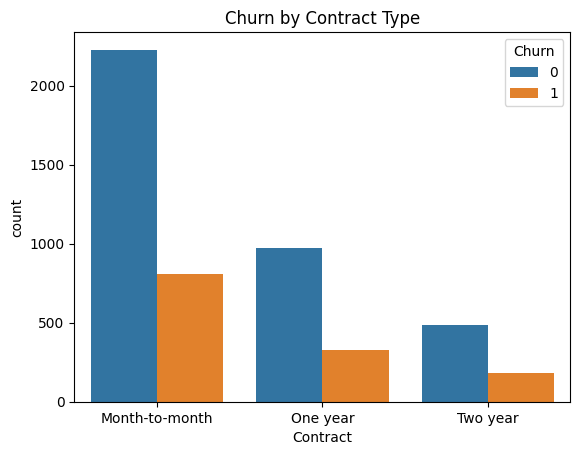

In [1295]:
sns.countplot(x="Contract", data = ConnectX_Churn, hue = "Churn")
plt.title("Churn by Contract Type")
plt.show()

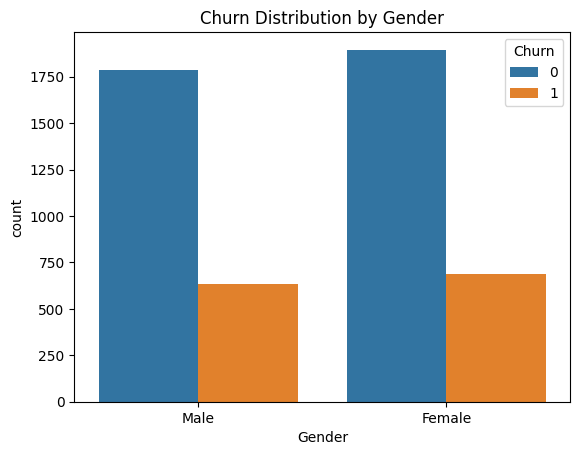

In [1296]:
sns.countplot(x="Gender", data=ConnectX_Churn, hue="Churn")
plt.title("Churn Distribution by Gender")
plt.show()

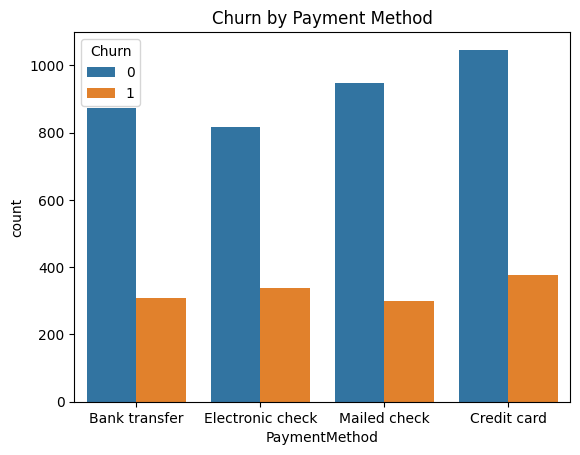

In [1297]:
sns.countplot(x="PaymentMethod", data = ConnectX_Churn, hue = "Churn")
plt.title("Churn by Payment Method")
plt.show()

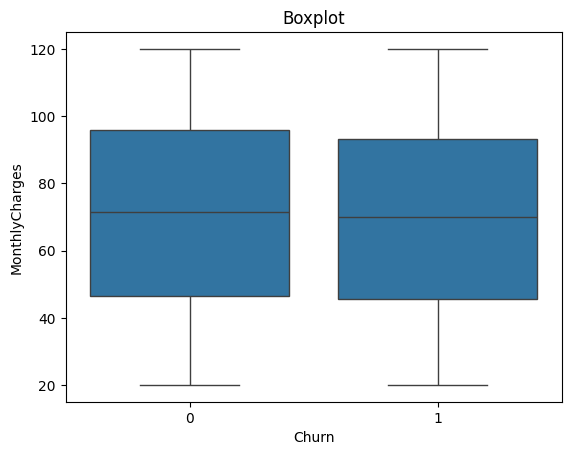

In [1298]:
sns.boxplot(x="Churn", y = "MonthlyCharges", data=ConnectX_Churn)
plt.title("Boxplot")
plt.show()

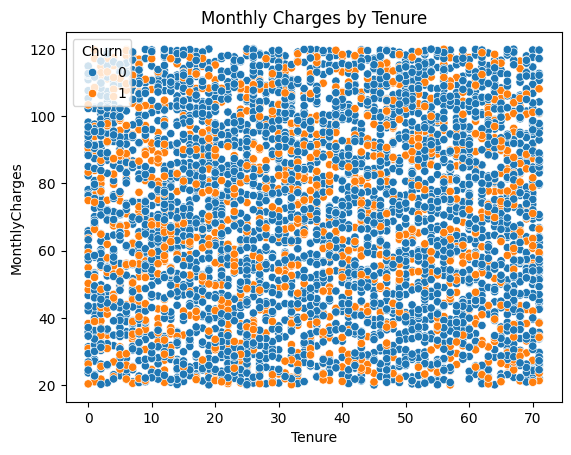

In [1299]:
sns.scatterplot(x='Tenure', y="MonthlyCharges", data=ConnectX_Churn, hue="Churn")
plt.title("Monthly Charges by Tenure")
plt.show()

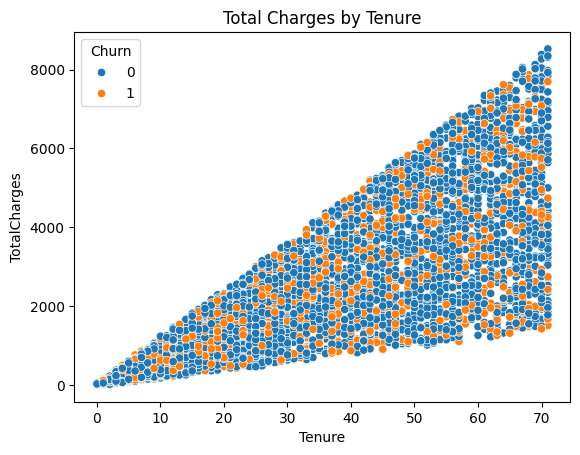

In [1300]:
sns.scatterplot(x='Tenure', y="TotalCharges", data=ConnectX_Churn, hue="Churn")
plt.title("Total Charges by Tenure")
plt.show()

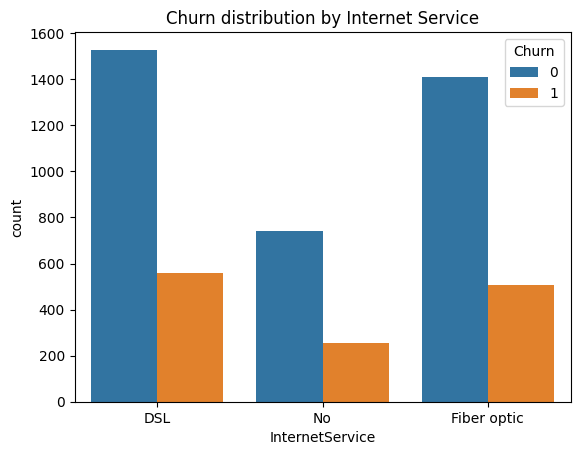

In [1301]:
sns.countplot(x="InternetService", data = ConnectX_Churn, hue="Churn")
plt.title("Churn distribution by Internet Service")
plt.show()

In [1302]:
ratio = ConnectX_Churn.groupby("InternetService")["Churn"].agg(["sum", "count"])
ratio["ChurnRate"] = ratio["sum"] / ratio["count"]
print("Churn Rate by Type of Service\n", ratio)

Churn Rate by Type of Service
                  sum  count  ChurnRate
InternetService                       
DSL              558   2086   0.267498
Fiber optic      508   1919   0.264721
No               254    995   0.255276


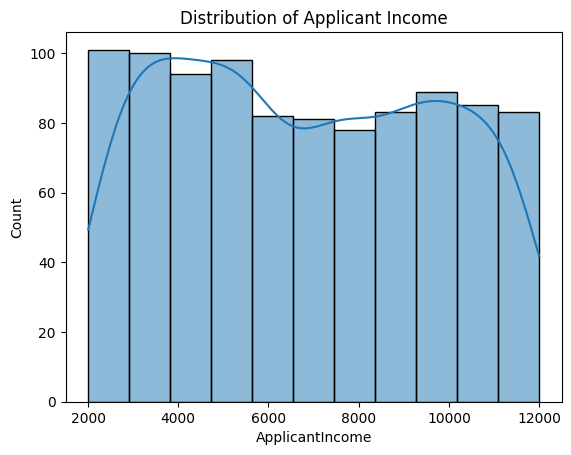

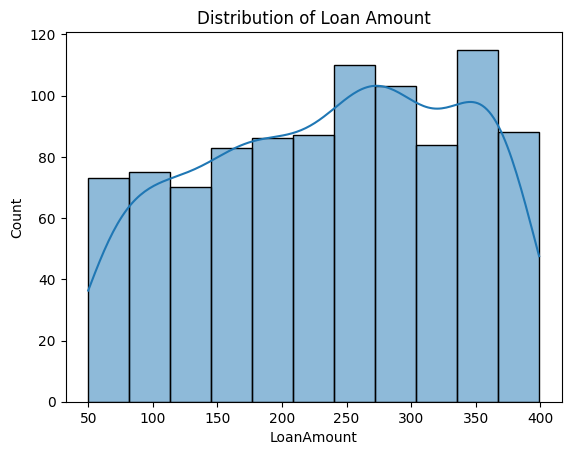

In [1303]:
sns.histplot(data=loan_approval, x='ApplicantIncome', kde=True)
plt.title('Distribution of Applicant Income')
plt.show()

sns.histplot(data=loan_approval, x='LoanAmount', kde=True)
plt.title('Distribution of Loan Amount')
plt.show()

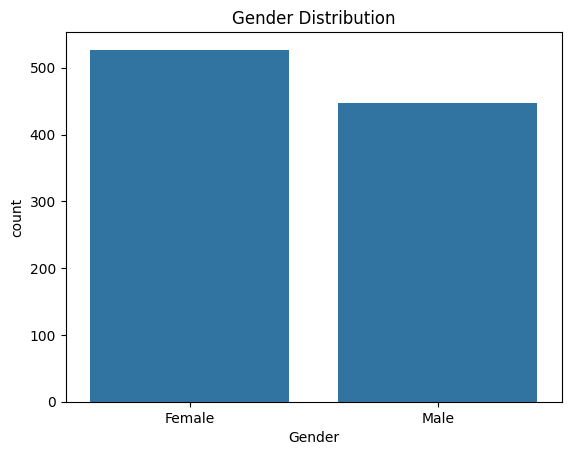

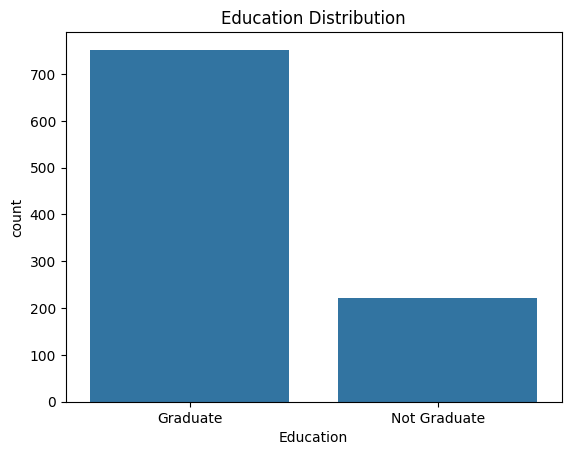

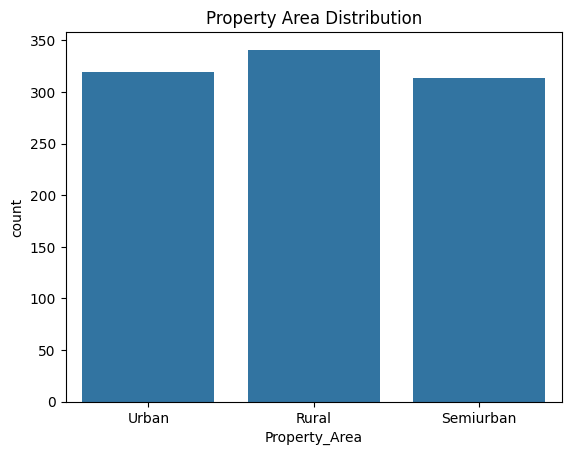

In [1304]:
sns.countplot(data=loan_approval, x='Gender')
plt.title('Gender Distribution')
plt.show()

sns.countplot(data=loan_approval, x='Education')
plt.title('Education Distribution')
plt.show()

sns.countplot(data=loan_approval, x='Property_Area')
plt.title('Property Area Distribution')
plt.show()

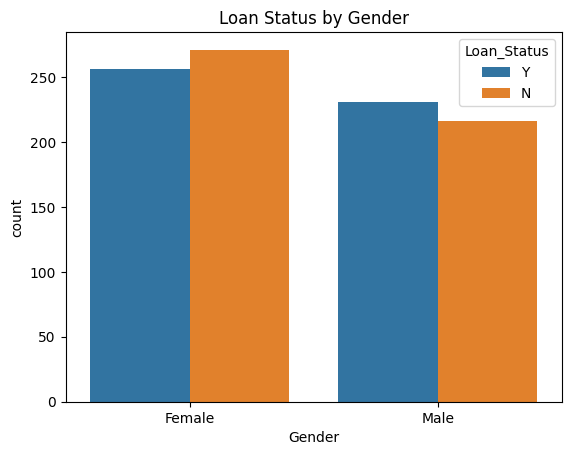

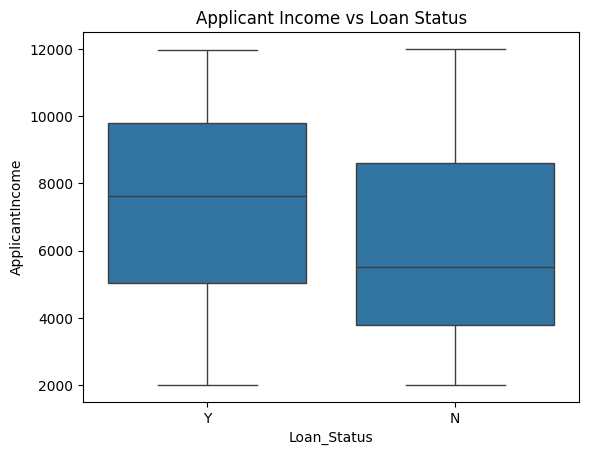

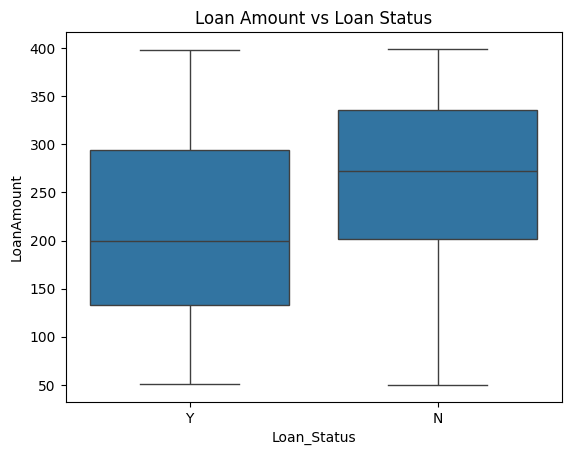

In [1305]:
sns.countplot(data=loan_approval, x='Gender', hue='Loan_Status')
plt.title('Loan Status by Gender')
plt.show()

sns.boxplot(data=loan_approval, x='Loan_Status', y='ApplicantIncome')
plt.title('Applicant Income vs Loan Status')
plt.show()

sns.boxplot(data=loan_approval, x='Loan_Status', y='LoanAmount')
plt.title('Loan Amount vs Loan Status')
plt.show()

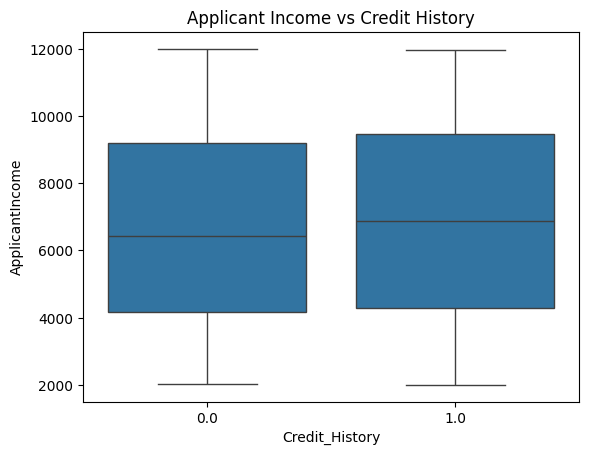

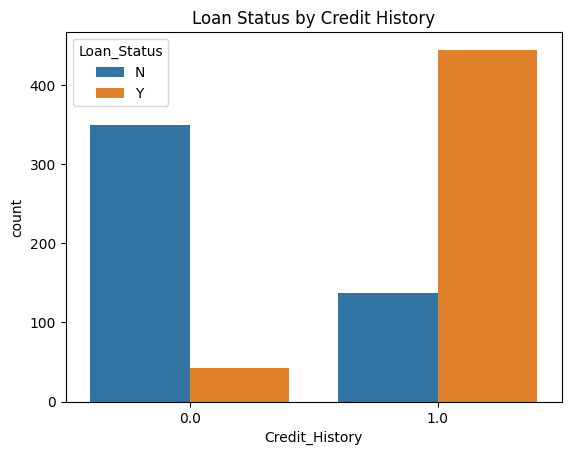

In [1306]:
sns.boxplot(data=loan_approval, x='Credit_History', y='ApplicantIncome')
plt.title('Applicant Income vs Credit History')
plt.show()

sns.countplot(data=loan_approval, x='Credit_History', hue='Loan_Status')
plt.title('Loan Status by Credit History')
plt.show()

In [1307]:
label_encoder = LabelEncoder()
loan_approval["Loan_Status"] = label_encoder.fit_transform(loan_approval["Loan_Status"])

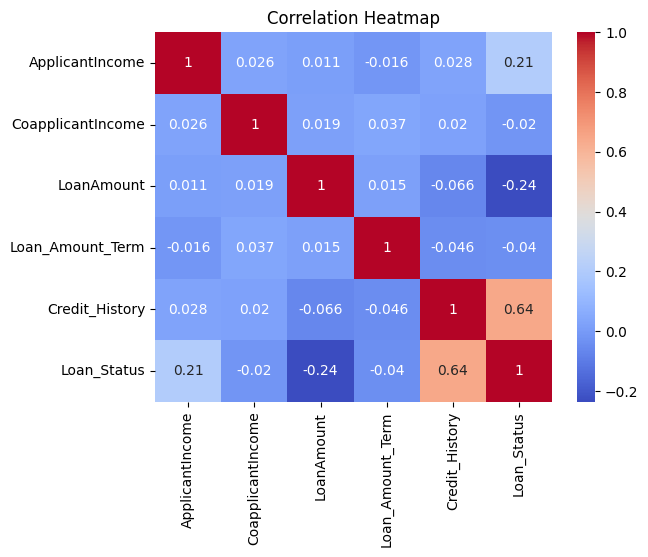

In [1308]:
sns.heatmap(loan_approval[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Loan_Status']].corr(), cmap="coolwarm", annot = True)
plt.title("Correlation Heatmap")
plt.show()

In [1309]:
loan_approval = pd.get_dummies(loan_approval, columns = ["Gender", "Married", "Education", "Self_Employed", "Property_Area"], drop_first = True)
loan_approval["Loan_Status"] = label_encoder.fit_transform(loan_approval["Loan_Status"])
loan_approval = loan_approval.drop("Loan_ID", axis = 1)

In [1310]:
ConnectX_Churn = pd.get_dummies(ConnectX_Churn, columns=["Gender", "InternetService", "Contract", "PaymentMethod"], drop_first = True)
print(ConnectX_Churn)
ConnectX_Churn = ConnectX_Churn.drop("CustomerID", axis = 1)

      CustomerID  Age  Tenure  MonthlyCharges  TotalCharges  Churn  \
0              1   68      65           27.68       1827.83      0   
1              2   64      53           59.29       3133.66      0   
2              3   64      26           86.99       2281.39      1   
3              4   21      37           66.99       2479.35      0   
4              5   24      57           58.37       3301.21      0   
...          ...  ...     ...             ...           ...    ...   
4995        4996   48       3           89.09        237.54      0   
4996        4997   30      54           99.93       5427.04      1   
4997        4998   33      33           69.33       2274.79      1   
4998        4999   60      26           36.52        998.09      1   
4999        5000   38       6           61.47        355.64      0   

      Gender_Male  InternetService_Fiber optic  InternetService_No  \
0            True                        False               False   
1           False  

In [1311]:
y = ConnectX_Churn["Churn"]
x = ConnectX_Churn.drop("Churn", axis=1)

In [1312]:
scaler = StandardScaler()
x[["Age", "Tenure", "MonthlyCharges", "TotalCharges"]] = scaler.fit_transform(x[["Age", "Tenure", "MonthlyCharges", "TotalCharges"]])

In [1313]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42, stratify=y)

In [1314]:
logistic_regression = LogisticRegression(max_iter = 1000, random_state = 42)
trained = logistic_regression.fit(x_train, y_train)

In [1315]:
results = trained.predict(x_test)
confusion = confusion_matrix(y_test, results)
print("Confusion Matrix:\n\n", confusion, "\nClassification Report:\n\n", classification_report(y_test, results))

Confusion Matrix:

 [[736   0]
 [264   0]] 
Classification Report:

               precision    recall  f1-score   support

           0       0.74      1.00      0.85       736
           1       0.00      0.00      0.00       264

    accuracy                           0.74      1000
   macro avg       0.37      0.50      0.42      1000
weighted avg       0.54      0.74      0.62      1000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [1316]:
random_forest = RandomForestClassifier(random_state=42)
trained = random_forest.fit(x_train, y_train)

In [1317]:
results = trained.predict(x_test)
confusion = confusion_matrix(y_test, results)
print("Confusion Matrix:\n\n", confusion, "\nClassification Report:\n\n", classification_report(y_test, results))

Confusion Matrix:

 [[715  21]
 [256   8]] 
Classification Report:

               precision    recall  f1-score   support

           0       0.74      0.97      0.84       736
           1       0.28      0.03      0.05       264

    accuracy                           0.72      1000
   macro avg       0.51      0.50      0.45      1000
weighted avg       0.61      0.72      0.63      1000



In [1318]:
loan_approval["TotalIncome"] = loan_approval["ApplicantIncome"] + loan_approval["CoapplicantIncome"]
loan_approval["Income_to_Loan_Ratio"] = loan_approval["TotalIncome"] / (loan_approval["LoanAmount"] + 1)

loan_approval["Dependents"] = loan_approval["Dependents"].replace("3+", 3).astype(float)
loan_approval["Family_Size"] = loan_approval["Dependents"] + 1

loan_approval["LoanAmount"] = np.log(loan_approval["LoanAmount"] + 1)

In [1319]:
numeric_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History", "TotalIncome", "Income_to_Loan_Ratio", "Family_Size"]

scaler = StandardScaler()
loan_approval[numeric_cols] = scaler.fit_transform(loan_approval[numeric_cols])

In [1320]:
y = loan_approval["Loan_Status"]
X = loan_approval.drop("Loan_Status", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (779, 15)
Test shape: (195, 15)


In [1321]:
logistic_regression = LogisticRegression(max_iter=1000, random_state=42)
lr_trained = logistic_regression.fit(X_train, y_train)

random_forest = RandomForestClassifier(n_estimators=200, random_state=42)
rf_trained = random_forest.fit(X_train, y_train)

In [1322]:
lr_pred = lr_trained.predict(X_test)
print("\n----- Logistic Regression Performance -----")
print("Confusion Matrix:\n", confusion_matrix(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

rf_pred = rf_trained.predict(X_test)
print("\n----- Random Forest Performance -----")
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

lr_acc = accuracy_score(y_test, lr_pred)
rf_acc = accuracy_score(y_test, rf_pred)

print("\nAccuracy Comparison:")
print("LR Accuracy:", lr_acc)
print("RF Accuracy:", rf_acc)


----- Logistic Regression Performance -----
Confusion Matrix:
 [[79 19]
 [10 87]]
              precision    recall  f1-score   support

           0       0.89      0.81      0.84        98
           1       0.82      0.90      0.86        97

    accuracy                           0.85       195
   macro avg       0.85      0.85      0.85       195
weighted avg       0.85      0.85      0.85       195


----- Random Forest Performance -----
Confusion Matrix:
 [[76 22]
 [ 1 96]]
              precision    recall  f1-score   support

           0       0.99      0.78      0.87        98
           1       0.81      0.99      0.89        97

    accuracy                           0.88       195
   macro avg       0.90      0.88      0.88       195
weighted avg       0.90      0.88      0.88       195


Accuracy Comparison:
LR Accuracy: 0.8512820512820513
RF Accuracy: 0.882051282051282



Top 5 Most Important Features:
 Credit_History          0.347505
Income_to_Loan_Ratio    0.111808
LoanAmount              0.111761
ApplicantIncome         0.103742
TotalIncome             0.084325
dtype: float64


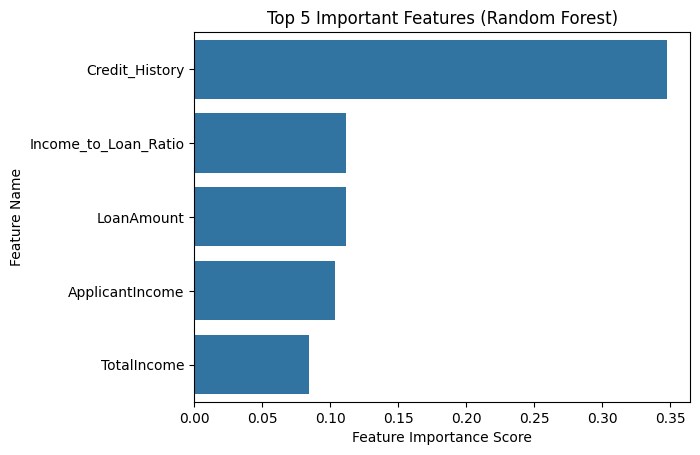

In [1323]:
importances = pd.Series(rf_trained.feature_importances_, index=X.columns)
top5 = importances.sort_values(ascending=False).head(5)

print("\nTop 5 Most Important Features:\n", top5)

sns.barplot(x=top5.values, y=top5.index)
plt.title("Top 5 Important Features (Random Forest)")
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature Name")
plt.show()